In [1]:
""""
Copyright (C) 2025 ETH Zurich, Stefan J.P. Chrin, Gregory Landrum, Sereina Riniker
"""

files = {
    "Meta-learner": "../../../A_MODELS/Z_META/DDG/RANDOM/ddG_ridge_LOO_pred&error.json",
    "FEP (OPLS3e)": "../../../A_MODELS/FEP/DDG/OPLS/OPLS_RANDOM_ddG_FROM_FEP_GRAPH_pred&error.json",
    "FEP (OFF)": "../../../A_MODELS/FEP/DDG/OFF/OFF_RANDOM_ddG_FROM_FEP_GRAPH_pred&error.json"
}

TARGETS_TO_SKIP = ("galectin","thrombin","p2")

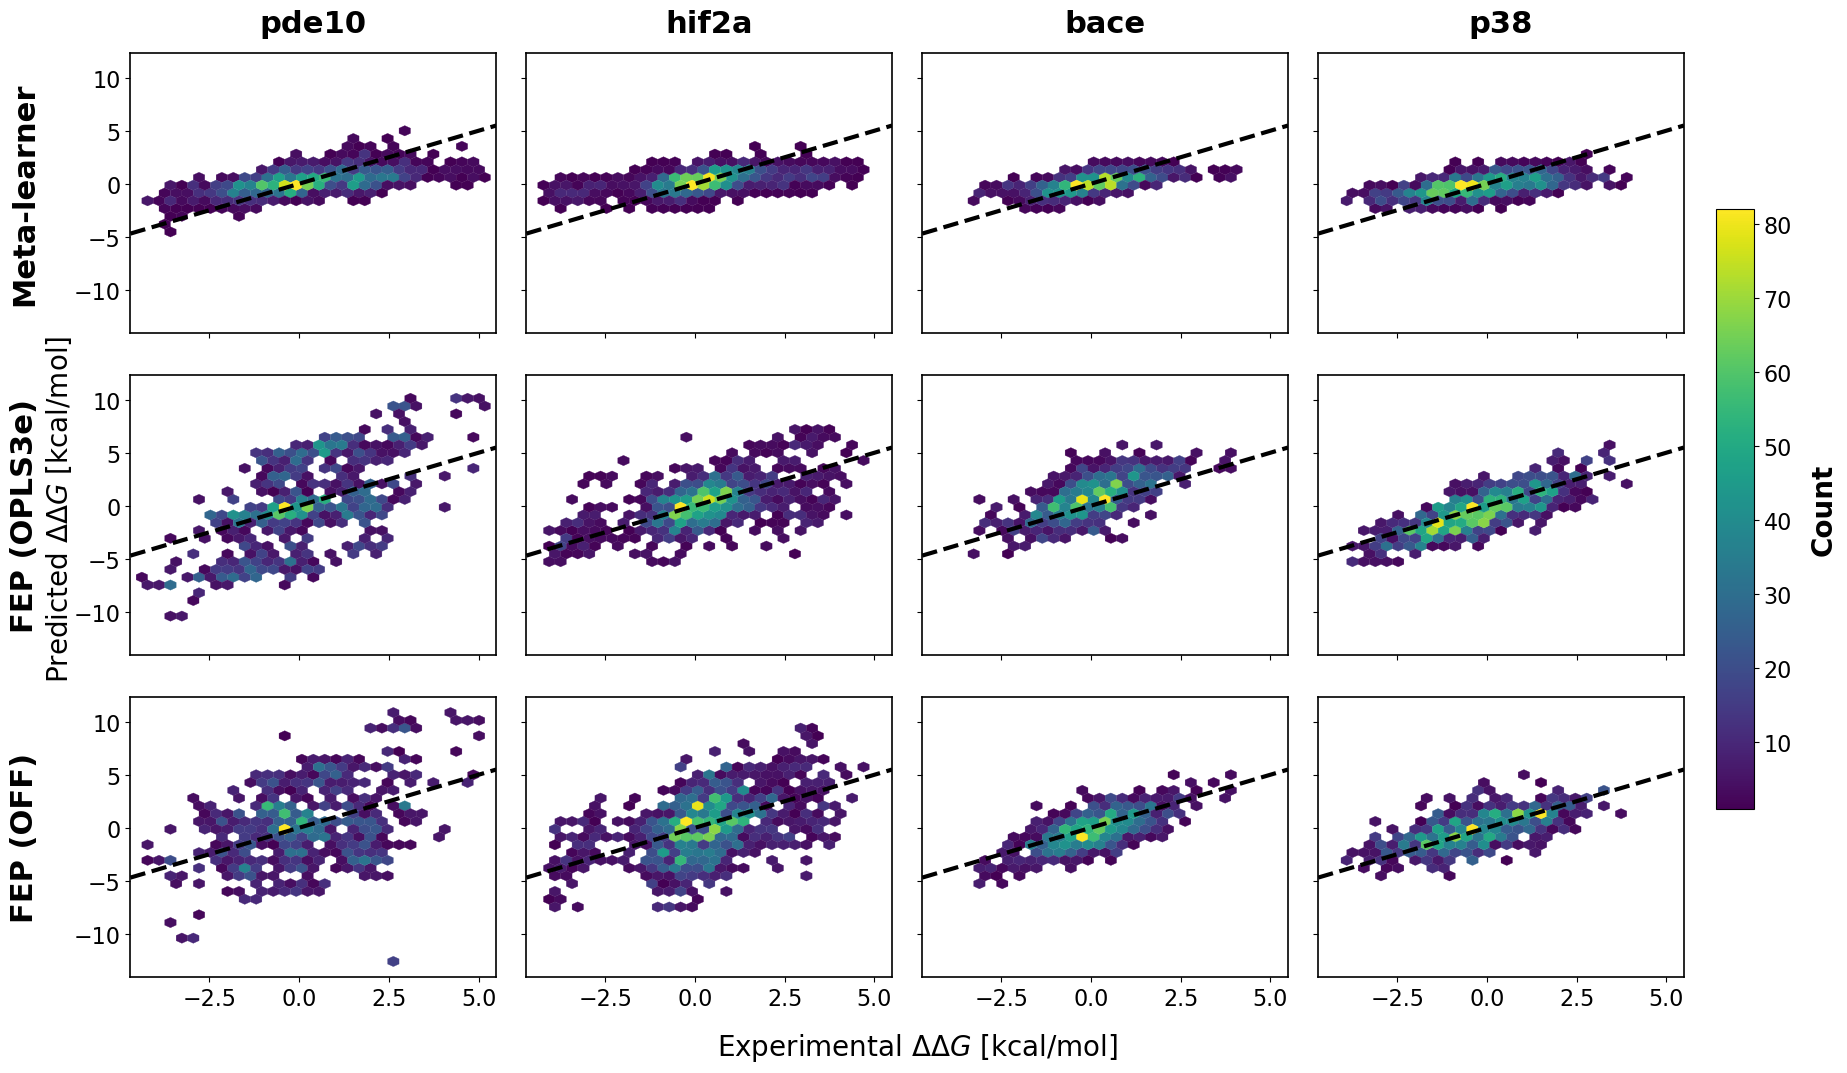

In [2]:
import json, numpy as np, matplotlib.pyplot as plt
from scipy.stats import linregress
import math

TITLE_FONT_SIZE = 22
METHOD_FONT_SIZE = 22
LABEL_FONT_SIZE = 20
TICK_FONT_SIZE = 16
lw_diag = 3.0
diag_alpha = 1.0
GRID_SIZE = 35
# hexbin gridsize - HIGHER = FINER BINS (try 10, 15, 20, 25, 30)
cmap_hexbin = "viridis"  # colormap for hexbin

def plot_pred_vs_true_hexbin(files, targets_to_plot, TARGETS_TO_SKIP, gridsize=15):
    """
    Inputs:
      files: dict method -> json path
      targets_to_plot: list of target names
      TARGETS_TO_SKIP: tuple of targets to skip
      gridsize: hexbin gridsize (higher = finer bins, try 10-30)
    Output:
      grid of hexbin plots with shared colorbar on right, uniform bin sizes
    """
    methods = list(files.keys())
    nrows = len(methods)
    ncols = len(targets_to_plot)

    # use GridSpec with extra column for colorbar - tighter spacing
    fig = plt.figure(figsize=(5*ncols + 1, 4*nrows))
    gs = fig.add_gridspec(nrows, ncols+1, width_ratios=[1]*ncols + [0.12], wspace=0.1, hspace=0.15)

    # build axes grid
    axes = []
    for r in range(nrows):
        row = []
        for c in range(ncols):
            row.append(fig.add_subplot(gs[r, c]))
        axes.append(row)
    axes = np.array(axes)

    all_x, all_y = [], []
    hexbin_collections = []  # store hexbin artists for colorbar

    # first pass: collect all data to get global limits
    for r, method in enumerate(methods):
        with open(files[method], "r") as f:
            data = json.load(f)

        for c, target in enumerate(targets_to_plot):
            if target in TARGETS_TO_SKIP:
                continue

            preds, exps = [], []
            for split in data:
                if target not in split:
                    continue
                for pair in sorted(split[target]):
                    v = split[target][pair]
                    preds.append(v["prediction"])
                    exps.append(v["experimental"])

            if preds:
                all_x += exps
                all_y += preds

    # global limits
    if all_x and all_y:
        x_min, x_max = min(all_x), max(all_x)
        y_min, y_max = min(all_y), max(all_y)
        # add small margin
        x_margin = (x_max - x_min) * 0.05
        y_margin = (y_max - y_min) * 0.05
        x_min -= x_margin
        x_max += x_margin
        y_min -= y_margin
        y_max += y_margin
    else:
        x_min, x_max, y_min, y_max = 0, 1, 0, 1

    # extent parameter for uniform hexbin sizing across all plots
    extent = [x_min, x_max, y_min, y_max]

    # second pass: create hexbin plots with consistent gridsize and extent
    for r, method in enumerate(methods):
        with open(files[method], "r") as f:
            data = json.load(f)

        for c, target in enumerate(targets_to_plot):
            ax = axes[r, c]

            if target in TARGETS_TO_SKIP:
                ax.axis("off")
                continue

            preds, exps = [], []
            for split in data:
                if target not in split:
                    continue
                for pair in sorted(split[target]):
                    v = split[target][pair]
                    preds.append(v["prediction"])
                    exps.append(v["experimental"])

            if not preds:
                ax.axis("off")
                continue

            # 1:1 diagonal line
            ax.plot(
                [x_min, x_max],
                [x_min, x_max],
                color="black",
                linewidth=lw_diag,
                alpha=diag_alpha,
                linestyle="--",
                zorder=1
            )

            # hexbin plot with consistent gridsize and extent for uniform bins
            hb = ax.hexbin(
                exps,
                preds,
                gridsize=gridsize,
                extent=extent,
                cmap=cmap_hexbin,
                mincnt=1,
                edgecolors='face',
                linewidths=0.2,
                zorder=0
            )
            hexbin_collections.append(hb)

            ax.set_xlim(x_min, x_max)
            ax.set_ylim(y_min, y_max)
            ax.tick_params(axis="both", labelsize=TICK_FONT_SIZE)

            # thicker subplot borders
            for spine in ax.spines.values():
                spine.set_linewidth(1.2)

            # y label - upright text with italic Greek letter
            if c == 0:
                ax.text(
                    -0.25, 0.5,
                    method,
                    transform=ax.transAxes,
                    rotation=90,
                    va="center",
                    ha="right",
                    fontsize=METHOD_FONT_SIZE,
                    fontweight='bold'
                )

            # title - bold
            if r == 0:
                ax.set_title(target,
                             fontsize=TITLE_FONT_SIZE,
                             pad=15,
                             fontweight='bold')

            # remove x/y ticklabels for interior plots
            if r != nrows - 1:
                ax.tick_params(axis="x", labelbottom=False)
            if c != 0:
                ax.tick_params(axis="y", labelleft=False)

    # single shared colorbar on right - spans 50% of full plot height, centered
    cbar_height = 0.5  # 50% of figure height
    cbar_bottom = 0.25  # center it (start at 25% to end at 75%)
    cbar_left = 0.88  # position from left (decrease for closer to plots)
    cbar_width = 0.018
    cax = fig.add_axes([cbar_left, cbar_bottom, cbar_width, cbar_height])
    
    if hexbin_collections:
        cb = fig.colorbar(hexbin_collections[0], cax=cax)
        cb.set_label("Count", fontsize=LABEL_FONT_SIZE, labelpad=13)
        cb.ax.yaxis.label.set_weight('bold')
        for t in cb.ax.get_yticklabels():
            t.set_fontsize(TICK_FONT_SIZE)

    # figure-level axis labels - appear only once
    fig.text(0.5, 0.045, r"$\mathrm{Experimental}$ $\Delta\Delta G$ $\mathrm{[kcal/mol]}$", 
             ha='center', fontsize=LABEL_FONT_SIZE)
    fig.text(0.091, 0.5, r"$\mathrm{Predicted}$ $\Delta\Delta G$ $\mathrm{[kcal/mol]}$", 
             ha='center', va='center', rotation=90, fontsize=LABEL_FONT_SIZE)

    plt.savefig("SLOPE.png", dpi=600, bbox_inches="tight")
    plt.show()


targets_to_plot = ["pde10", "hif2a", "bace", "p38"]
plot_pred_vs_true_hexbin(files, targets_to_plot, TARGETS_TO_SKIP, gridsize=32)